## Zachary's Karate Club: Spectral Modularity

We start by loading Zachary's Karate Club graph (34 nodes and 78 edges) and computing a single `spring_layout` with a fixed seed. Keeping the node coordinates fixed ensures that when we plot the graph after each split, the nodes stay in the same positions and only their community colors change.

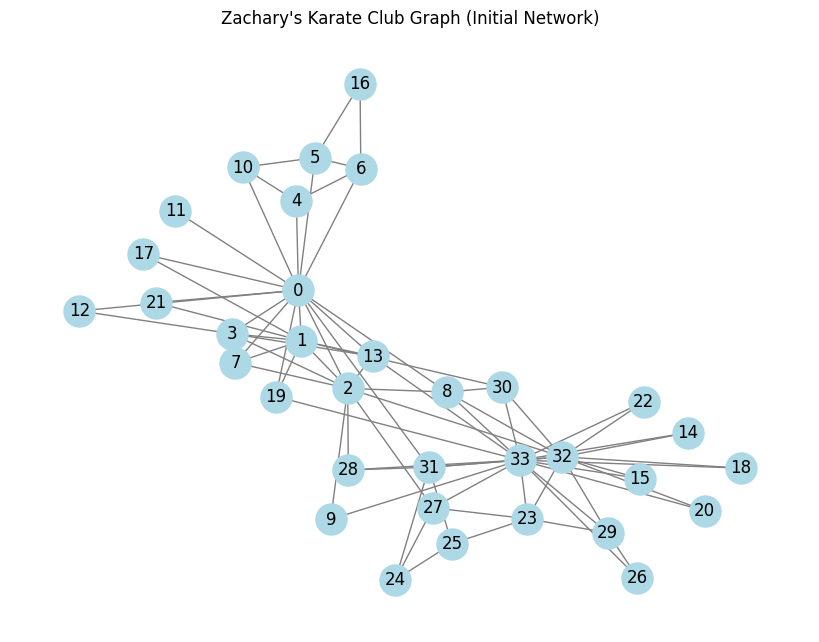

Nodes: 34 Edges: 78


In [1]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

G = nx.karate_club_graph()
nodes = sorted(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()

pos = nx.spring_layout(G, seed = 1) # use seed = 1 to check later

plt.figure(figsize=(8, 6))
nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray", node_size=500)
plt.title("Zachary's Karate Club Graph (Initial Network)")
plt.show()

print("Nodes:", n, "Edges:", m)

### Modularity Matrix Construction

Next, we build the unweighted $34 \times 34$ adjacency matrix $A$ (`weight=None` ensures all edges have weight 1) and compute the degree vector $k$. Using these, we construct the global modularity matrix $B = A - \frac{kk^\top}{2m}$, which compares actual connections against the expected edges under a degree-preserving random null model. Checking that the maximum row sum is near zero verifies $B\mathbf{1} = \mathbf{0}$.

In [2]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = np.sum(A, axis=1)
B = A - np.outer(k, k) / (2 * m)

print("B shape:", B.shape)
print("Max row sum of B:", np.max(np.abs(np.sum(B, axis=1))))

B shape: (34, 34)
Max row sum of B: 8.881784197001252e-16



We keep a list `active_communities` initialized with all 34 nodes and a dictionary `metrics_history` to store node metrics at each step. After every split, `record_and_plot` colors the nodes by their current community and computes degree, betweenness, closeness, and clustering on `G_current`, which retains only edges within the same community so we can observe how the metrics change as communities separate.

In [3]:
active_communities = [list(nodes)]
metrics_history = {}
iteration = 0

def record_and_plot(step):
    color_map = [0] * n
    for group_id, comm in enumerate(active_communities):
        for node in comm:
            color_map[node] = group_id

    plt.figure(figsize=(8, 6))
    nx.draw(
        G,
        pos,
        with_labels=True,
        node_color=color_map,
        cmap=plt.cm.Set3,
        edge_color="gray",
        node_size=500
    )
    plt.title(f"Iteration {step}: {len(active_communities)} Communities")
    plt.show()

    G_current = nx.Graph()
    G_current.add_nodes_from(nodes)
    for comm in active_communities:
        sub = G.subgraph(comm)
        G_current.add_edges_from(sub.edges())

    metrics_history[step] = {
        "degree": nx.degree_centrality(G_current),
        "betweenness": nx.betweenness_centrality(G_current),
        "closeness": nx.closeness_centrality(G_current),
        "clustering": nx.clustering(G_current)
    }

Given a community $C$, `spectral_bisect` extracts the restricted submatrix $B^{(C)}$ from $B$ and uses `np.linalg.eigh` to find its largest eigenvalue $\lambda_1^{(C)}$ and leading eigenvector $u_1^{(C)}$. If $\lambda_1^{(C)} \le 0$ (within floating-point tolerance), no split increases modularity and the recursion stops on that branch. Otherwise, nodes are split into `C_plus` and `C_minus` based on the signs of $u_1^{(C)}$, checked for positive modularity gain $\Delta Q = \frac{1}{4m} s^\top B^{(C)} s$, and partitioned recursively.

In [4]:
def spectral_bisect(C):
    global iteration

    if len(C) <= 1:
        return

    B_C = B[C][:, C]
    eigvals, eigvecs = np.linalg.eigh(B_C)

    lam1 = eigvals[-1]
    u1 = eigvecs[:, -1]

    if lam1 <= 1e-10:
        return

    C_plus = []
    C_minus = []
    s = np.zeros(len(C))

    for i in range(len(C)):
        if u1[i] > 0:
            C_plus.append(C[i])
            s[i] = 1
        else:
            C_minus.append(C[i])
            s[i] = -1

    delta_Q = (s @ B_C @ s) / (4 * m)

    if len(C_plus) == 0 or len(C_minus) == 0 or delta_Q <= 1e-10:
        return

    active_communities.remove(C)
    active_communities.append(C_plus)
    active_communities.append(C_minus)

    iteration += 1
    record_and_plot(iteration)

    spectral_bisect(C_plus)
    spectral_bisect(C_minus)


We record the baseline metrics at Iteration 0 and run `spectral_bisect` starting from the full node set until all remaining groups have nonpositive leading eigenvalues.

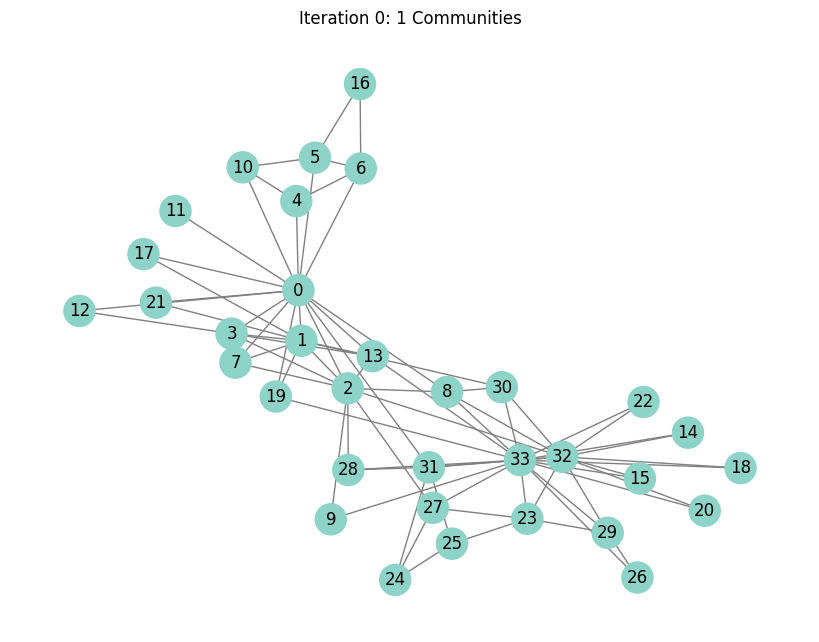

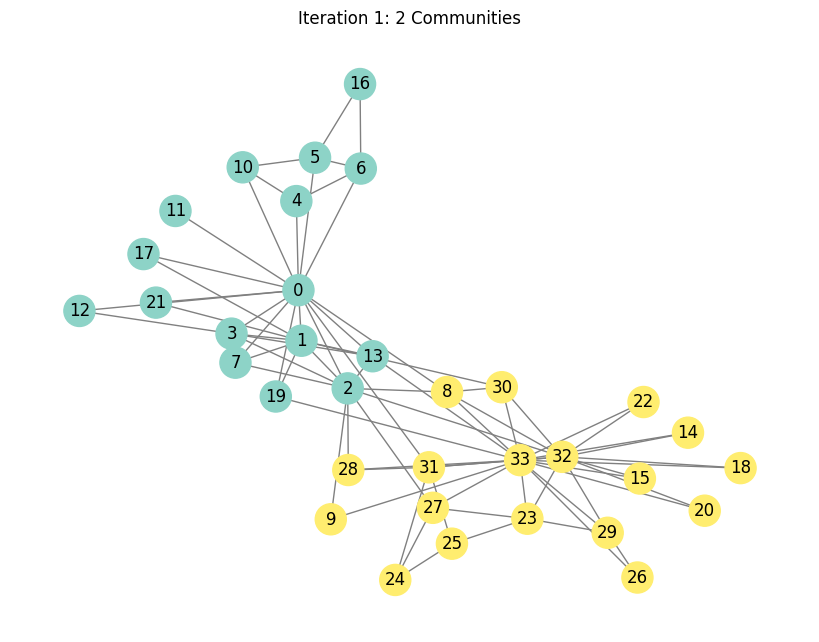

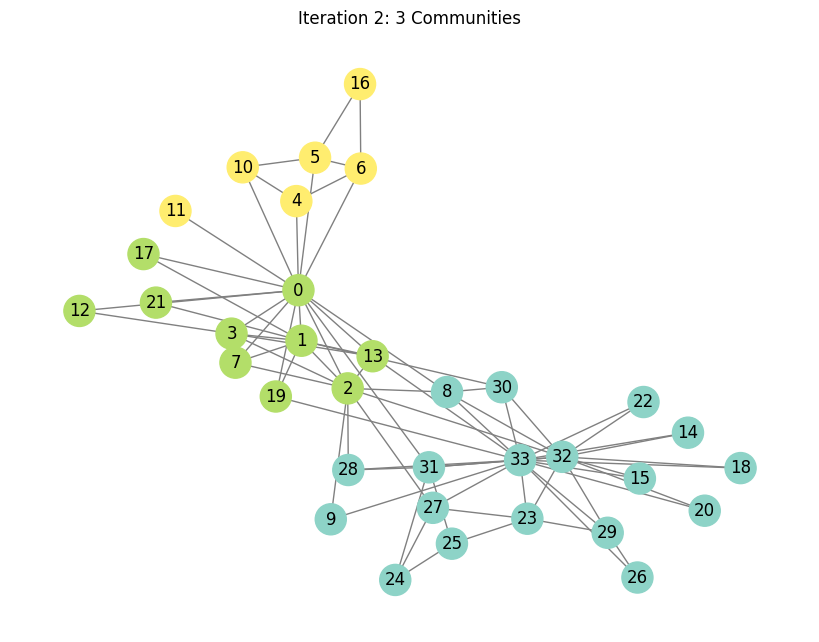

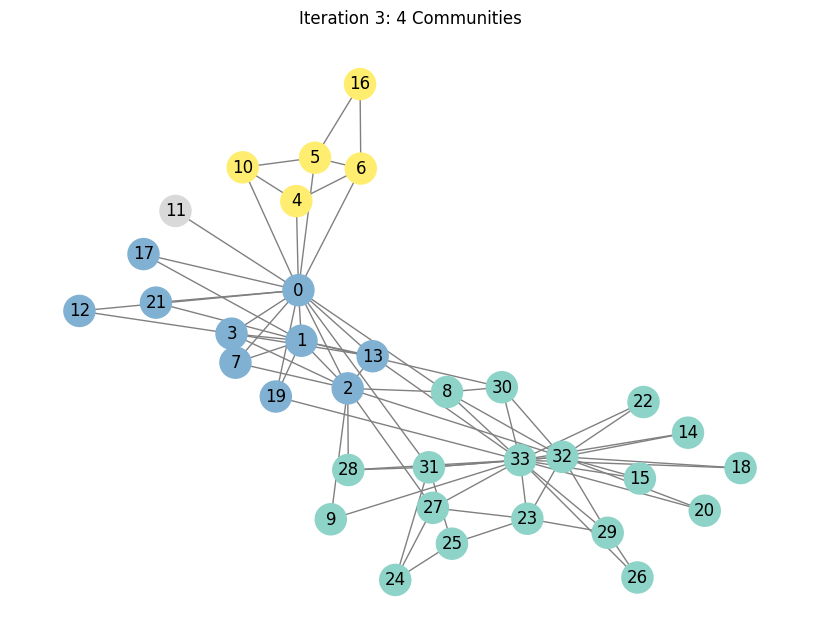

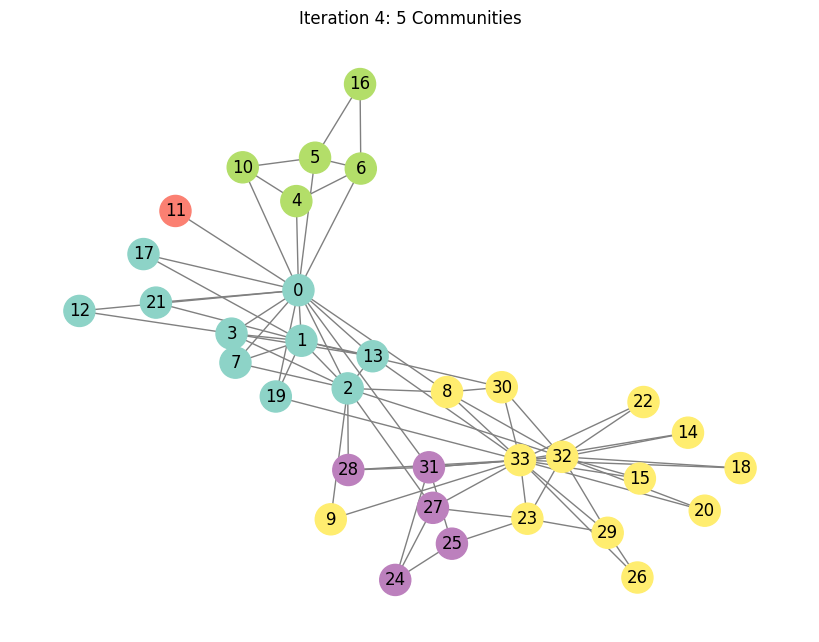

Final number of communities: 5
Community 1: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 2: [11]
Community 3: [4, 5, 6, 10, 16]
Community 4: [24, 25, 27, 28, 31]
Community 5: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]


In [5]:
record_and_plot(0)
spectral_bisect(active_communities[0])

print("Final number of communities:", len(active_communities))
for idx, comm in enumerate(active_communities):
    print(f"Community {idx + 1}:", sorted(comm))


Using `metrics_history`, we plot how each of the four metrics changes across iterations for all 34 nodes, highlighting key hub nodes (0, 1, 2, 32, and 33) while keeping the rest in light gray for readability.

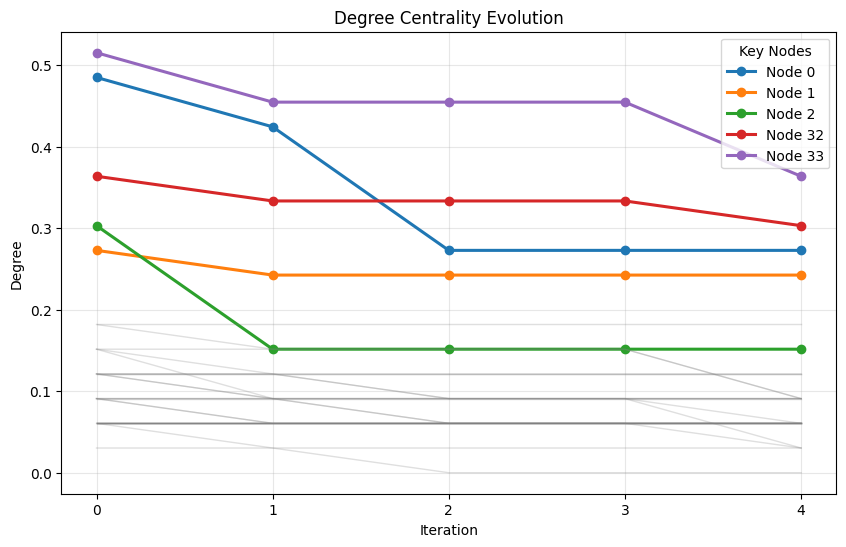

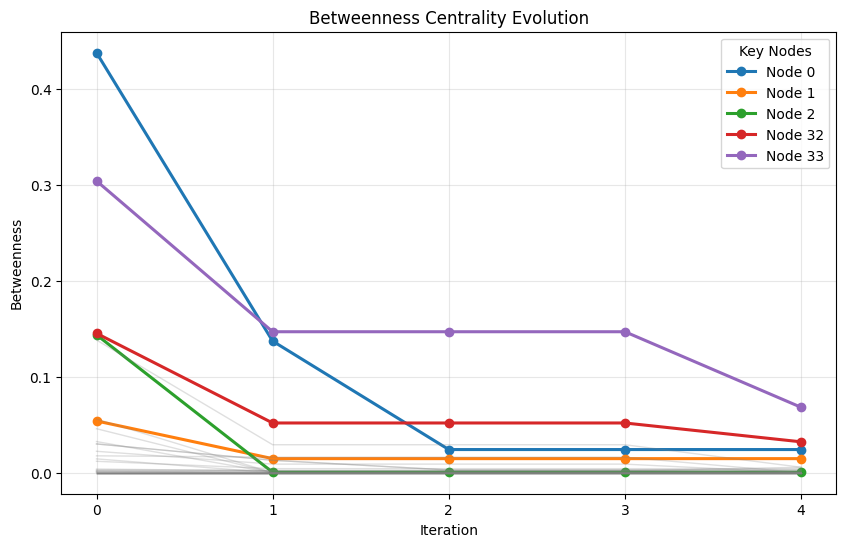

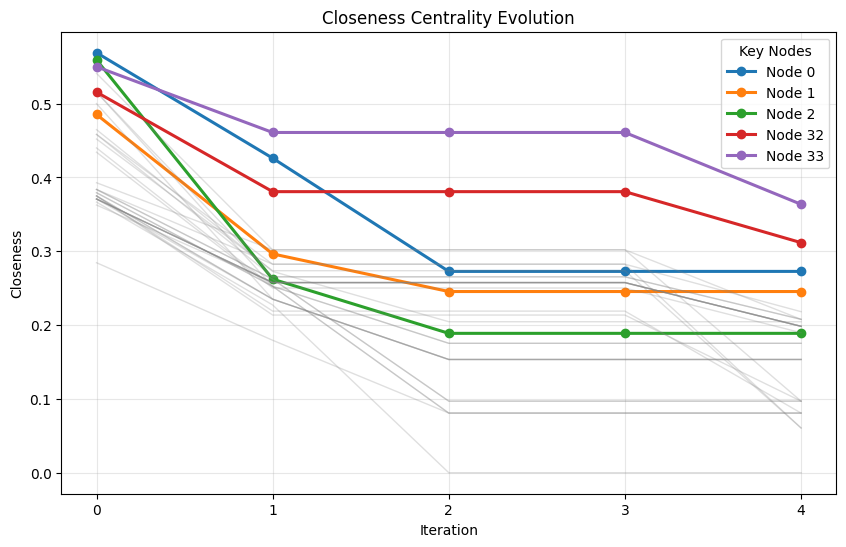

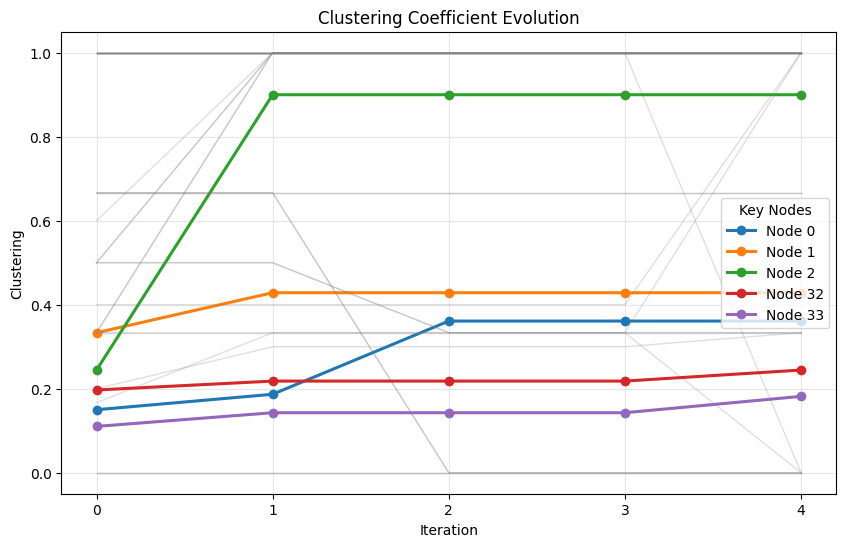

In [6]:
metrics_list = ["degree", "betweenness", "closeness", "clustering"]
titles = [
    "Degree Centrality Evolution",
    "Betweenness Centrality Evolution",
    "Closeness Centrality Evolution",
    "Clustering Coefficient Evolution"
]
iterations = sorted(metrics_history.keys())
key_nodes = [0, 1, 2, 32, 33]

for metric, title in zip(metrics_list, titles):
    plt.figure(figsize=(10, 6))
    for node in nodes:
        values = [metrics_history[it][metric][node] for it in iterations]
        if node in key_nodes:
            plt.plot(iterations, values, marker="o", linewidth=2.2, label=f"Node {node}")
        else:
            plt.plot(iterations, values, color="gray", alpha=0.25, linewidth=1)

    plt.title(title)
    plt.xlabel("Iteration")
    plt.ylabel(metric.capitalize())
    plt.xticks(iterations)
    plt.grid(True, alpha=0.3)
    plt.legend(title="Key Nodes", loc="best")
    plt.show()

### Method Attribution

The modularity matrix $B$, modularity objective $Q$, and recursive spectral bipartition algorithm used here follow Newman, M. E. J. (2006), "Modularity and community structure in networks," *Proceedings of the National Academy of Sciences (PNAS)*, 103(23):8577–8582.

### Discussion

1. **Comparison with the Historical Split:**
   In Iteration 1, the leading eigenvector divides the graph into two main groups centered around Node 0 (Mr. Hi) and Node 33 (the club president). This closely matches the historical split recorded by Zachary, with only a few boundary nodes (such as Node 8, which has ties to both sides) grouped with the president's side. Continuing the recursion splits these two factions further into [X] final sub-communities before all submatrices have $\lambda_1^{(C)} \le 0$.

2. **Consistently Central Nodes:**
   Nodes 0 and 33, along with closely connected members like Nodes 1, 2, and 32, remain the most central nodes inside their respective communities across all iterations. Because they form the core of their local friend groups, cutting edges between rival factions removes very few of their internal connections.

3. **Effect of Community Splits on Node Metrics:**
   * **Betweenness Centrality:** Nodes 0 and 33 start with very high betweenness in Iteration 0 because shortest paths between the two halves of the club pass through them. Once Iteration 1 cuts the cross-faction edges, their betweenness drops sharply, though they remain the main local bridges within their own groups.
   * **Degree and Closeness Centrality:** Both metrics decrease in steps as inter-community edges are removed and nodes lose paths to vertices outside their own component.
   * **Clustering Coefficient:** Local clustering remains relatively stable (and even rises for several core nodes) because triangles in the network are concentrated within tightly knit groups rather than across different communities.